# 01 · Preprocessing dan Baseline Heuristik (RCAEval RE1–RE3)

Notebook ini menjelaskan langkah demi langkah bagaimana data metrik RCAEval diubah menjadi input model, lalu menghitung **baseline heuristik** yang menjadi pembanding untuk model SSL.

**Tugas:** lokalisasi root cause. Untuk setiap kasus gangguan, tebak **service** mana yang menjadi sumber masalah.

**Alur preprocessing per kasus:**

1. Baca `metrics.parquet` dan `inject_time.txt`.
2. Ambil label dari nama folder: sistem, root-cause service, dan jenis fault.
3. Pilih service aplikasi, lalu bentuk kanal tetap K = 5: `cpu, mem, latency-50, latency-90, workload`, beserta **mask**.
4. Samakan grid waktu ke 1 detik dan isi nilai yang hilang.
5. Normalisasi *robust z-score* per series memakai statistik **sebelum injeksi**.
6. Potong window `[inject − 300 s, inject + 240 s)`, sehingga T = 540.
7. Hasilnya tensor `x` berukuran `[N_service, T, K]`, `mask` berukuran `[N_service, K]`, dan `label` = indeks root service.

Semua logika ada di `src/ssl_rcl/data.py`. Notebook ini mengulang langkah-langkahnya secara manual untuk satu kasus, lalu memastikan hasilnya identik dengan fungsi `load_case`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ssl_rcl.data import (CORE_METRICS, EXCLUDED_CASES, NON_APP_SERVICES, list_cases, select_services,
                          load_case, build_samples, stratified_split, make_pretrain_windows,
                          collate_cases, case_meta_table, _robust_stats)

DATA = ROOT / "dataset"
pd.set_option("display.width", 160, "display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110

## 1. Struktur data mentah

Setiap kasus adalah satu folder. Nama folder sudah berisi label:

```
re2ob_checkoutservice_cpu_1
│  │ │               │   └─ ulangan ke-1
│  │ │               └───── jenis fault (cpu/mem/disk/delay/loss/socket, atau f1–f5 di RE3)
│  │ └───────────────────── root-cause service  ← INI LABEL YANG DICARI
│  └─────────────────────── sistem: ob = Online Boutique, ss = Sock Shop, tt = Train Ticket
└────────────────────────── dataset: RE1/RE2/RE3
```

Isi folder:
- `metrics.parquet`: kolom `time` (detik, epoch) dan kolom `<service>_<metrik>`.
- `inject_time.txt`: waktu fault disuntikkan.
- `logs.parquet` dan `traces.parquet`: hanya ada di RE2/RE3, dan **tidak dipakai** karena RE1 hanya punya metrik.

In [2]:
cases = list_cases(DATA, ["RE1", "RE2", "RE3"])
print("Jumlah kasus valid:", len(cases))
print("Kasus yang dikeluarkan:", EXCLUDED_CASES)
pd.DataFrame([dict(re=c.re, system=c.system, root_service=c.root_service, fault=c.fault) for c in cases]) \
  .groupby(["re", "system"]).agg(n=("fault", "size"), root_services=("root_service", lambda s: sorted(set(s))),
                                 faults=("fault", lambda s: sorted(set(s))))

Jumlah kasus valid: 733
Kasus yang dikeluarkan: {'re1ob_productcatalogservice_cpu_3', 're1ob_currencyservice_loss_1'}


n                                      root_services                                 faults
re  system                                                                                               
RE1 ob      123  [adservice, cartservice, checkoutservice, curr...          [cpu, delay, disk, loss, mem]
    ss      125          [carts, catalogue, orders, payment, user]          [cpu, delay, disk, loss, mem]
    tt      125  [ts-auth-service, ts-order-service, ts-route-s...          [cpu, delay, disk, loss, mem]
RE2 ob       90  [checkoutservice, currencyservice, emailservic...  [cpu, delay, disk, loss, mem, socket]
    ss       90          [carts, catalogue, orders, payment, user]  [cpu, delay, disk, loss, mem, socket]
    tt       90  [ts-auth-service, ts-order-service, ts-route-s...  [cpu, delay, disk, loss, mem, socket]
RE3 ob       30  [adservice, cartservice, currencyservice, emai...                   [f1, f2, f3, f4, f5]
    ss       30                         [carts, front-end, orders]                       [f1, f2, f3, f4]
    tt       30                [ts-auth-service, ts-route-service]                       [f1, f2, f3, f4]

In [3]:
meta = next(c for c in cases if c.name == "re2ob_checkoutservice_cpu_1")
raw = pd.read_parquet(meta.path / "metrics.parquet")
inject = int((meta.path / "inject_time.txt").read_text())
print(meta)
print("shape:", raw.shape, "| inject_time:", inject,
      "| detik sebelum injeksi:", inject - raw.time.min(), "| sesudah:", raw.time.max() - inject)
raw.iloc[:3, :10]

CaseMeta(name='re2ob_checkoutservice_cpu_1', re='RE2', system='ob', root_service='checkoutservice', fault='cpu', rep=1, path=PosixPath('/Users/fauzan/Developer/machine learning/ssl-rcl/dataset/RE2/re2ob_checkoutservice_cpu_1'))
shape: (1441, 73) | inject_time: 1705354566 | detik sebelum injeksi: 720 | sesudah: 720


,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853


### Dua kasus yang dikeluarkan
- `re1ob_currencyservice_loss_1`: isi `inject_time.txt` adalah `16933142`. Angka ini tampaknya terpotong, karena data berjalan dari 1693313863 sampai 1693314583.
- `re1ob_productcatalogservice_cpu_3`: datanya hanya 62 detik, dan waktu injeksinya berada di luar rentang data.

Akibatnya RE1 berisi 373 kasus, bukan 375.

## 2. Memilih service

Nama kolom dipecah di garis bawah terakhir: `ts-auth-service_latency-90` menjadi (`ts-auth-service`, `latency-90`).

Tidak semua "service" di kolom adalah service aplikasi. Ada kontainer infrastruktur (`istio-init`, `PassthroughCluster`, `frontend-check`, `main`), dan di RE3-ob bahkan ada sisa pod Sock Shop yang hanya punya `mem`/`socket`.

**Aturannya:** sebuah service dipakai jika punya kolom `cpu` **dan** tidak termasuk daftar infrastruktur. Service diurutkan alfabetis, sehingga indeks label konsisten.

In [4]:
all_services = sorted({c.rpartition("_")[0] for c in raw.columns if c != "time"})
chosen = select_services(raw.columns, meta.root_service)
print("Semua 'service' di kolom :", all_services)
print("Dibuang                 :", sorted(set(all_services) - set(chosen)))
print("Dipakai (N=%d)           :" % len(chosen), chosen)
print("Label = indeks root service", repr(meta.root_service), "=", chosen.index(meta.root_service))

Semua 'service' di kolom : ['adservice', 'cartservice', 'checkoutservice', 'currencyservice', 'emailservice', 'frontend', 'frontend-external', 'paymentservice', 'productcatalogservice', 'recommendationservice', 'redis', 'shippingservice']
Dibuang                 : ['frontend-external']
Dipakai (N=11)           : ['adservice', 'cartservice', 'checkoutservice', 'currencyservice', 'emailservice', 'frontend', 'paymentservice', 'productcatalogservice', 'recommendationservice', 'redis', 'shippingservice']
Label = indeks root service 'checkoutservice' = 2


## 3. Kanal metrik tetap (K = 5) dan mask

Sistem dan dataset berbeda punya jumlah kolom yang berbeda (50–370 kolom), sehingga tidak bisa langsung dijadikan satu input. Solusinya adalah membuat setiap service punya **5 kanal yang sama**:

| Kanal | Arti |
|---|---|
| `cpu` | pemakaian CPU kontainer |
| `mem` | pemakaian memori |
| `latency-50` | latensi median (p50) |
| `latency-90` | latensi persentil 90 |
| `workload` | jumlah request |

Kelima metrik ini ada di ketiga RE. `diskio` dan `socket` hanya ada di RE2/RE3, sedangkan `error` sebagian besar konstan. Ketiganya tidak dipakai.

Jika suatu service tidak punya kanal tertentu (misalnya database tidak punya latensi), kanal itu diisi 0 dan **mask = 0**. Model nanti bisa memakai mask ini untuk tahu kanal mana yang benar-benar ada.

Contoh kedua di bawah adalah RE1-ob dengan **skema lama** (50 kasus cpu/mem). Di skema ini, `latency-50`, `latency-90`, dan `workload` tidak ada sama sekali (kolomnya bernama `latency`/`load` dengan arti yang berbeda), sehingga semuanya di-mask.

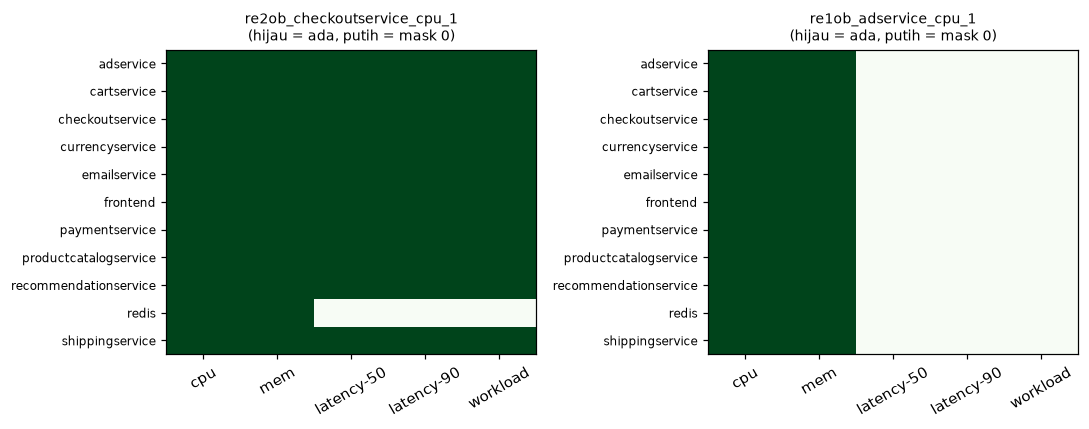

In [5]:
def mask_table(case_name):
    m = next(c for c in cases if c.name == case_name)
    cols = pd.read_parquet(m.path / "metrics.parquet").columns
    svcs = select_services(cols)
    return pd.DataFrame([[int(f"{s}_{k}" in cols) for k in CORE_METRICS] for s in svcs],
                        index=svcs, columns=CORE_METRICS)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["re2ob_checkoutservice_cpu_1", "re1ob_adservice_cpu_1"]):
    t = mask_table(name)
    ax.imshow(t.values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(CORE_METRICS)), CORE_METRICS, rotation=30)
    ax.set_yticks(range(len(t)), t.index, fontsize=8)
    ax.set_title(f"{name}\n(hijau = ada, putih = mask 0)", fontsize=9)
plt.tight_layout()

## 4. Grid waktu, nilai hilang, dan normalisasi

**Grid waktu.** Data di-*reindex* ke grid 1 detik penuh. Celah diisi dengan *forward fill* lalu *backward fill*. Series yang seluruhnya kosong ikut di-mask.

**Normalisasi robust z-score per series.** Setiap series (satu service × satu metrik) dinormalisasi dengan statistik dari **periode sebelum injeksi** (kondisi normal):

$$z_t = \mathrm{clip}\left(\frac{x_t - \mathrm{median}(x_{pre})}{s},\ -10,\ 10\right), \qquad s = 1.4826 \cdot \mathrm{MAD}(x_{pre})$$

Jika MAD = 0 (series hampir konstan), dipakai std. Jika std juga 0, dipakai 1.

Alasan pemilihan ini:
- **Skala antar dataset berbeda jauh.** Contohnya, cpu RE1-ob median ±4 sementara dataset lain <1, dan memori bernilai ~10⁸. Setelah z-score, semua kanal berada di skala yang sama, sehingga encoder bisa ditransfer.
- **Statistik diambil dari periode normal**, sehingga nilai z menyatakan *seberapa jauh menyimpang dari kondisi normal*. Inilah sinyal yang relevan untuk RCA.
- **Median/MAD dipakai alih-alih mean/std** karena lebih tahan terhadap spike sesaat.
- **Clip ±10** mencegah series yang baseline-nya hampir konstan menghasilkan nilai sangat ekstrem.

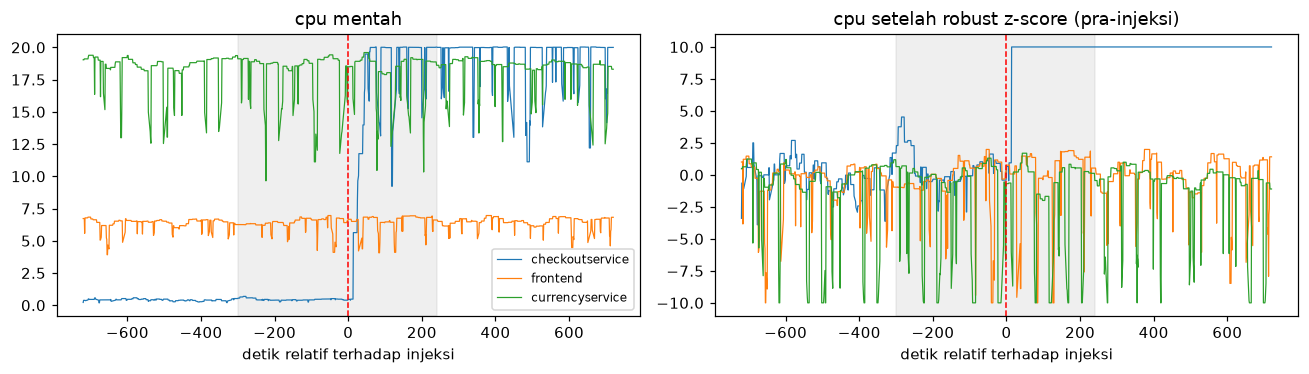

In [6]:
df = raw.drop_duplicates("time").set_index("time").sort_index()
t0, t1 = int(df.index.min()), int(df.index.max())
cols = [f"{s}_{k}" for s in chosen for k in CORE_METRICS]
present = np.array([c in df.columns for c in cols]).reshape(len(chosen), -1)

full = df.reindex(index=np.arange(t0, t1 + 1), columns=cols).astype(float).ffill().bfill()
values = full.to_numpy()
mask = present & ~np.isnan(values).all(0).reshape(len(chosen), -1)

med, scale = _robust_stats(values[: inject - t0])          # statistik pra-injeksi saja
z = np.nan_to_num(np.clip((values - med) / scale, -10, 10))
z[:, ~mask.reshape(-1)] = 0

# Visualisasi: CPU root service vs service lain, mentah vs ternormalisasi
show = [meta.root_service, "frontend", "currencyservice"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
tt = np.arange(t0, t1 + 1) - inject
for s in show:
    j = cols.index(f"{s}_cpu")
    axes[0].plot(tt, values[:, j], lw=0.8, label=s)
    axes[1].plot(tt, z[:, j], lw=0.8, label=s)
for ax, title in zip(axes, ["cpu mentah", "cpu setelah robust z-score (pra-injeksi)"]):
    ax.axvline(0, color="red", ls="--", lw=1); ax.axvspan(-300, 240, color="grey", alpha=0.12)
    ax.set_title(title); ax.set_xlabel("detik relatif terhadap injeksi")
axes[0].legend(fontsize=8)
plt.tight_layout()

Garis merah adalah waktu injeksi, dan area abu-abu adalah window yang dipakai. Setelah normalisasi, CPU root service (`checkoutservice`) melonjak jauh di atas service lain, sedangkan service normal tetap di sekitar 0.

## 5. Window `[inject − 300 s, inject + 240 s)`

Batas window dipilih supaya **semua kasus** punya data yang cukup:

| | Pra-injeksi (min) | Pasca-injeksi (min) |
|---|---|---|
| RE1 | 360 s | 246 s (RE1-ss) |
| RE2 | 720 s | **209 s** (`re2ob_checkoutservice_cpu_2`) |
| RE3 | 720 s | 720 s |

Jadi 300 detik sebelum dan 240 detik sesudah injeksi aman untuk hampir semua kasus. Satu-satunya pengecualian adalah `re2ob_checkoutservice_cpu_2`: 30 detik terakhirnya di-padding dengan nilai terakhir, dan jumlahnya dicatat di `pad_post`.

Normalisasi tetap memakai **seluruh** periode pra-injeksi (bukan hanya 300 detik di dalam window), supaya estimasi kondisi normal lebih stabil.

In [7]:
start, end = inject - 300, inject + 240
x_manual = z[start - t0: end - t0].reshape(540, len(chosen), -1).transpose(1, 0, 2).astype(np.float32)

s = load_case(meta)                       # fungsi di src/ssl_rcl/data.py
print("x:", s["x"].shape, "| mask:", s["mask"].shape, "| label:", s["label"], "->", s["services"][s["label"]],
      "| inject_offset:", s["inject_offset"])
print("Hasil manual identik dengan load_case:", np.allclose(x_manual, s["x"]) and (mask == s["mask"]).all())

x: (11, 540, 5) | mask: (11, 5) | label: 2 -> checkoutservice | inject_offset: 300
Hasil manual identik dengan load_case: True


## 6. Seluruh dataset

`build_samples` menjalankan `load_case` untuk semua kasus dan menyimpan hasilnya di `cache/` supaya pemanggilan berikutnya cepat.

Jumlah service per sistem sama di semua RE, kecuali tt: RE2/RE3 punya 4 database tambahan, sehingga 68 vs 64. Karena encoder bekerja **per service**, jumlah service yang berbeda tidak menjadi masalah.

In [8]:
samples = build_samples(DATA, ["RE1", "RE2", "RE3"], cache_dir=ROOT / "cache")
meta_df = case_meta_table(samples)
meta_df.groupby(["re", "system"]).agg(n=("name", "size"), n_service=("n_services", "max"),
                                      T=("T", "max"), n_root=("root_service", "nunique"),
                                      kanal_dimask_rata2=("masked_channels", "mean")).round(1)

RE1: 373 kasus


RE2: 270 kasus
RE3: 90 kasus


n  n_service    T  n_root  kanal_dimask_rata2
re  system                                                 
RE1 ob      123         11  540       5                15.0
    ss      125         15  540       5                21.0
    tt      125         64  540       5               116.0
RE2 ob       90         11  540       5                 3.0
    ss       90         15  540       5                24.0
    tt       90         68  540       5               122.4
RE3 ob       30         11  540       4                 3.0
    ss       30         15  540       3                21.0
    tt       30         68  540       2               125.0

## 7. Split train/val/test dan window pre-training

- **Split 60/20/20 terstratifikasi** per (sistem, root service) dengan seed 42. Tujuannya agar setiap root service muncul di train, val, dan test dengan proporsi yang mirip. Ini penting untuk RE3 yang kecil (90 kasus).
- **Window pre-training SSL** hanya diambil dari split **train**. Pre-training tidak memakai label, tetapi jika kasus test ikut dilihat saat pre-training, evaluasinya menjadi kurang adil (*transductive leakage*).
- Setiap window pre-training berbentuk satu service `[T, K]`. Di sinilah model SSL (TS2Vec/TimeMAE) belajar representasi tanpa label.

In [9]:
rows = []
for re_name in ["RE1", "RE2", "RE3"]:
    sub = [x for x in samples if x["re"] == re_name]
    tr, va, te = stratified_split(sub)
    w = make_pretrain_windows([sub[i] for i in tr], length=540, stride=540)
    rows.append(dict(re=re_name, train=len(tr), val=len(va), test=len(te), window_pretrain=w.shape))
pd.DataFrame(rows)

,re,train,val,test,window_pretrain
0,RE1,223,75,75,"(6728, 540, 5)"
1,RE2,165,60,45,"(5170, 540, 5)"
2,RE3,53,19,18,"(1677, 540, 5)"


In [10]:
b = collate_cases(samples[:4])
{k: tuple(v.shape) for k, v in b.items() if hasattr(v, "shape")}

{'x': (4, 11, 540, 5),
 'channel_mask': (4, 11, 5),
 'service_mask': (4, 11),
 'label': (4,)}

Batch untuk fine-tuning di-*padding* pada dimensi service, karena sistem yang berbeda punya N yang berbeda. `service_mask` menandai service mana yang asli.

---

## 8. Baseline heuristik

### Cara kerja
Baseline ini **tanpa pembelajaran sama sekali**:

1. Untuk setiap service, hitung **rata-rata |z|** pada periode **setelah injeksi**, hanya di kanal yang tidak di-mask.
2. Urutkan service dari yang paling menyimpang.
3. Prediksinya adalah service dengan penyimpangan terbesar.

Intuisinya, service yang terkena fault biasanya paling jauh berubah dari kondisi normalnya.

### Metrik evaluasi (standar RCA)
- **AC@k**: proporsi kasus di mana root service benar ada di k tebakan teratas.
- **Avg@5** = rata-rata AC@1 … AC@5.

In [11]:
def heuristic_scores(s):
    post = np.abs(s["x"][:, s["inject_offset"]:])                  # [N, T_post, K]
    m = s["mask"][:, None, :]
    return (post * m).sum((1, 2)) / np.maximum(m.sum((1, 2)) * post.shape[1], 1)

def rank_of_root(s):
    sc = heuristic_scores(s)
    return int((sc > sc[s["label"]]).sum()) + 1

meta_df["rank"] = [rank_of_root(s) for s in samples]

def summarize(r):
    return pd.Series({f"AC@{k}": (r <= k).mean() for k in (1, 3, 5)} |
                     {"Avg@5": np.mean([(r <= k).mean() for k in range(1, 6)]), "n": len(r)})

meta_df.groupby(["re", "system"])["rank"].apply(summarize).unstack().round(3)

AC@1   AC@3   AC@5  Avg@5      n
re  system                                   
RE1 ob      0.724  0.976  1.000  0.925  123.0
    ss      0.824  1.000  1.000  0.958  125.0
    tt      0.624  0.808  0.912  0.787  125.0
RE2 ob      0.889  0.978  1.000  0.958   90.0
    ss      0.822  0.989  1.000  0.949   90.0
    tt      0.656  0.800  0.844  0.776   90.0
RE3 ob      0.867  1.000  1.000  0.973   30.0
    ss      0.800  0.967  1.000  0.947   30.0
    tt      0.567  0.867  0.967  0.833   30.0

### Catatan: pembagi pada rata-rata
Skor di atas dirata-rata atas **kanal aktif saja**. Ada varian lain yang membagi dengan K = 5 penuh, sehingga kanal ter-mask dihitung sebagai 0.

Varian itu diam-diam **menguntungkan service yang punya banyak kanal**, yaitu service aplikasi dengan latensi dan workload, dibanding database yang hanya punya cpu/mem. Kebetulan root service di dataset ini selalu service aplikasi, sehingga angkanya terlihat lebih tinggi, terutama di Train Ticket yang punya banyak database. Itu adalah bias struktural, bukan kemampuan mendeteksi. Karena itu, baseline resmi memakai **kanal aktif**.

In [12]:
def rank_full_k(s):
    sc = (np.abs(s["x"][:, s["inject_offset"]:]) * s["mask"][:, None, :]).mean((1, 2))
    return int((sc > sc[s["label"]]).sum()) + 1

cmp = meta_df.assign(rank_fullK=[rank_full_k(s) for s in samples]).groupby(["re", "system"]).agg(
    AC1_kanal_aktif=("rank", lambda r: (r <= 1).mean()), AC1_bagi_K_penuh=("rank_fullK", lambda r: (r <= 1).mean()))
cmp.round(3)

AC1_kanal_aktif  AC1_bagi_K_penuh
re  system                                   
RE1 ob                0.724             0.732
    ss                0.824             0.896
    tt                0.624             0.800
RE2 ob                0.889             0.889
    ss                0.822             0.922
    tt                0.656             0.844
RE3 ob                0.867             0.933
    ss                0.800             0.867
    tt                0.567             0.900

### Contoh satu kasus
Heatmap di bawah menunjukkan |z| per service sepanjang waktu (rata-rata kanal aktif). Root service ditandai dengan panah.

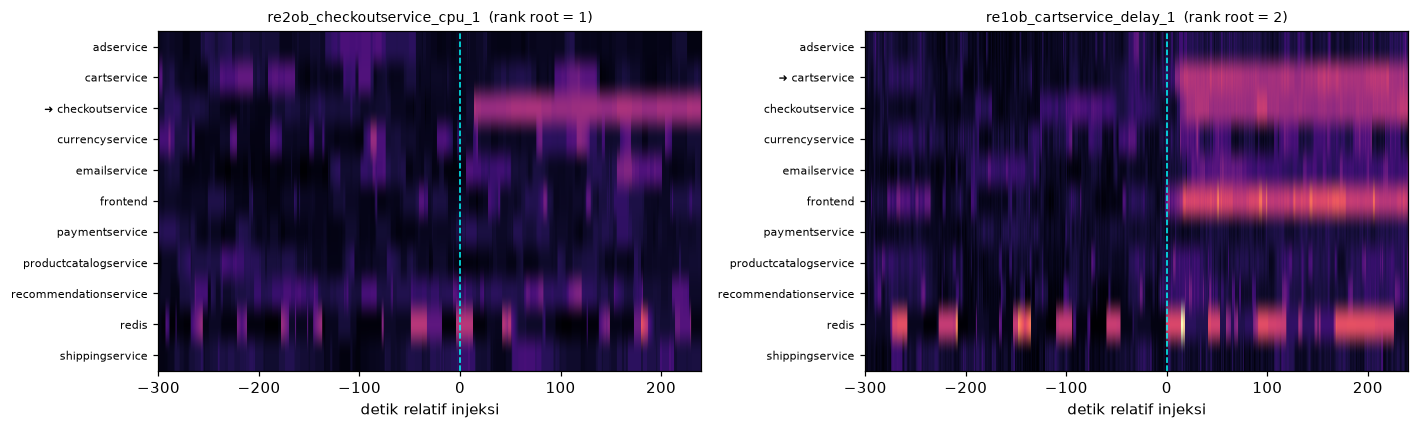

In [13]:
def plot_case(name, ax):
    s = next(x for x in samples if x["name"] == name)
    a = (np.abs(s["x"]) * s["mask"][:, None, :]).sum(2) / np.maximum(s["mask"].sum(1, keepdims=True), 1)
    ax.imshow(a, aspect="auto", cmap="magma", vmin=0, vmax=10, extent=[-300, 240, len(a) - .5, -.5])
    ax.axvline(0, color="cyan", ls="--", lw=1)
    ax.set_yticks(range(len(a)), [("➜ " if i == s["label"] else "") + n for i, n in enumerate(s["services"])], fontsize=7)
    ax.set_title(f"{name}  (rank root = {rank_of_root(s)})", fontsize=9); ax.set_xlabel("detik relatif injeksi")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_case("re2ob_checkoutservice_cpu_1", axes[0])
plot_case("re1ob_cartservice_delay_1", axes[1])
plt.tight_layout()

### Per jenis fault
Baseline kuat pada fault sumber daya (cpu, mem) karena root service sendiri langsung berubah. Baseline melemah pada fault jaringan (delay, loss). Pada fault jaringan, efeknya sering lebih terlihat di service **pemanggil** (latensinya naik) daripada di root service itu sendiri. Kasus seperti inilah yang memberi ruang bagi model yang belajar pola, bukan sekadar besarnya penyimpangan.

In [14]:
meta_df.pivot_table(index=["re", "fault"], columns="system", values="rank",
                    aggfunc=lambda r: (r <= 1).mean()).round(2).rename_axis(columns="AC@1 per sistem")

AC@1 per sistem    ob    ss    tt
re  fault                        
RE1 cpu          1.00  1.00  0.88
    delay        0.32  0.56  0.32
    disk         1.00  0.96  0.80
    loss         0.29  0.68  0.12
    mem          1.00  0.92  1.00
RE2 cpu          1.00  0.93  0.93
    delay        0.60  0.53  0.33
    disk         1.00  0.73  0.80
    loss         0.73  0.80  0.07
    mem          1.00  1.00  0.93
    socket       1.00  0.93  0.87
RE3 f1           0.67  0.70  0.71
    f2           1.00  0.67  0.57
    f3           0.83  0.90  0.30
    f4           1.00  0.86  0.83
    f5           1.00   NaN   NaN

### Baseline pada split test
Hasil di atas dihitung di semua kasus karena baseline tidak dilatih. Untuk perbandingan yang adil dengan model SSL nanti, berikut nilai pada **split test** yang sama dengan yang akan dipakai model.

In [15]:
test_rows = []
for re_name in ["RE1", "RE2", "RE3"]:
    idx = meta_df.index[meta_df.re == re_name].to_numpy()
    _, _, te = stratified_split([samples[i] for i in idx])
    sub = meta_df.loc[idx[te]]
    test_rows.append(summarize(sub["rank"]).rename(re_name))
pd.DataFrame(test_rows).round(3)

,AC@1,AC@3,AC@5,Avg@5,n
RE1,0.813,0.960,0.987,0.923,75.0
RE2,0.800,0.911,0.956,0.898,45.0
RE3,0.667,0.944,1.000,0.900,18.0


### Catatan penting tentang baseline
1. **Baseline ini cukup kuat, dengan AC@1 0.57–0.89 dan AC@3 0.80–1.00.** Penyebabnya, window dipusatkan di waktu injeksi dan normalisasi memakai periode normal. Model SSL baru bermakna jika **mengungguli** baseline ini.
   - Ruang perbaikan terbesar ada di **Train Ticket (tt)**, dengan AC@1 0.57–0.66.
   - Ruang perbaikan juga ada di fault **delay dan loss**: AC@1 di RE1 hanya 0.12–0.68, dan RE1-tt loss hanya 0.12.
   - Sebaliknya, fault cpu/mem/disk hampir selalu benar.
2. **Setting ini mengasumsikan waktu injeksi (anomali) diketahui.** Setting yang sama dipakai metode RCA di benchmark RCAEval, dan biasanya waktu ini berasal dari tahap deteksi anomali.
3. **Confound di RE1-ob:** semua kasus cpu/mem memakai skema lama (3 kanal ter-mask), sedangkan delay/loss/disk memakai skema baru. Untuk lokalisasi service hal ini tidak membocorkan label, tetapi hasil sebaiknya juga dilaporkan per jenis fault.
4. Untuk laporan, baseline ini sebaiknya dilengkapi dengan baseline RCA standar dari RCAEval (misalnya BARO atau metode statistik lain) agar posisi model SSL jelas.

## Ringkasan

| Langkah | Keputusan |
|---|---|
| Kasus | 733 (RE1 373, RE2 270, RE3 90); 2 kasus RE1 rusak dikeluarkan |
| Service | punya `cpu` dan bukan infrastruktur; ob 11, ss 15, tt 64/68 |
| Kanal | K = 5 (`cpu, mem, latency-50, latency-90, workload`) + mask |
| Normalisasi | robust z-score per series dari periode pra-injeksi, clip ±10 |
| Window | `[−300 s, +240 s)` → T = 540 |
| Label | indeks root-cause service |
| Split | 60/20/20 terstratifikasi (sistem, root service), seed 42 |
| Pre-training | window per service, hanya dari split train |
| Baseline | ranking rata-rata \|z\| pasca-injeksi (atas kanal aktif) |